# 📘 Chapter 4 — Training Linear Models (My Notes)
## Part 2 — Gradient Descent

*Continues from Part 1 (essentials + the Normal Equation). Picking up straight where we left off.*


### 2.0 — Setup

This notebook is meant to run standalone, so let's recreate the exact same dataset from Part 1
first (same seed, so the numbers below match).


In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from sklearn.preprocessing import add_dummy_feature

np.random.seed(42)
m = 100
X = 2 * np.random.rand(m, 1)
y = 4 + 3 * X + np.random.randn(m, 1)

X_b = add_dummy_feature(X)
X_new = np.array([[0], [2]])
X_new_b = add_dummy_feature(X_new)


### 2.1 — Why Gradient Descent at all?

We already have an exact, one-shot answer (the Normal Equation) — so why do we need another
method? Two reasons:

1. **Cost.** Computing $(\mathbf X^\top \mathbf X)^{-1}$ is roughly $O(n^3)$ in the number of
   features $n$. Fine for a few hundred features; painfully slow — or outright infeasible — once
   $n$ reaches the tens of thousands.
2. **Generality.** The Normal Equation only exists because linear regression's MSE happens to
   have a nice closed-form minimum. Plenty of other cost functions don't — including Logistic
   Regression's, later in this chapter. Gradient Descent is a general-purpose optimization
   method: it works on (almost) any differentiable cost function, not just this one.

Rule of thumb: reach for the Normal Equation when the feature count is small; reach for Gradient
Descent when it's large, or when there's no closed form to begin with.


### 2.2 — The core idea, in one picture

Picture $J(\boldsymbol\theta)$ as a bowl-shaped surface over the space of possible
$\boldsymbol\theta$ values (we already know it's convex, from Part 1). Gradient Descent starts
at some point on that surface and repeatedly asks *"which direction is downhill from here?"*,
then takes a small step that way. Repeat until you stop moving.

The gradient $\nabla_{\boldsymbol\theta}J(\boldsymbol\theta)$ points in the direction of
**steepest increase** — so stepping in the *opposite* direction is the fastest way downhill,
locally. That gives the update rule every variant below shares:

$$\boldsymbol\theta \leftarrow \boldsymbol\theta - \eta\,\nabla_{\boldsymbol\theta}J(\boldsymbol\theta)$$

where $\eta$ ("eta") is the **learning rate** — how big a step to take.


### 2.3 — Batch Gradient Descent

Recall from Part 1: $\nabla_{\boldsymbol\theta}\text{MSE}(\boldsymbol\theta) = \frac{2}{m}\mathbf X^\top(\mathbf X\boldsymbol\theta - \mathbf y)$
— the exact same expression we set to zero to *derive* the Normal Equation. This time, instead
of solving algebraically for where it equals zero, we just repeatedly walk downhill along it.

**"Batch"** means every single step uses the *entire* training set (all $m$ instances) to
compute the gradient. One full pass through all $m$ instances is called an **epoch**.


In [2]:
eta = 0.1          # learning rate
n_epochs = 1000

np.random.seed(42)
theta = np.random.randn(2, 1)   # random initialization -- we have to start somewhere

for epoch in range(n_epochs):
    gradients = 2 / m * X_b.T @ (X_b @ theta - y)
    theta = theta - eta * gradients

theta


array([[4.21509616],
       [2.77011339]])

That should land on `[[4.21509616], [2.77011339]]` — the **exact same numbers** the Normal
Equation gave us in Part 1. Reassuring: two completely different methods (one exact and
algebraic, one iterative and approximate) converge to the same answer.


### 2.4 — The learning rate matters, a lot

- Too **small** an $\eta$: convergence is safe but painfully slow — you might need far more than
  `n_epochs` to get close to the optimum.
- Too **large** an $\eta$: each step can overshoot the minimum, and the path bounces around, or
  even diverges (moves further and further away instead of converging).

Let's see it rather than just describe it — same setup, three different learning rates.


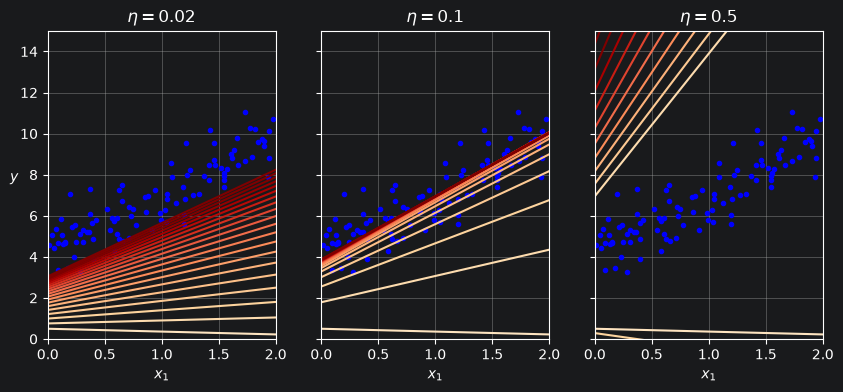

In [3]:
def plot_gradient_descent(theta, eta):
    m = len(X_b)
    plt.plot(X, y, "b.")
    n_epochs = 1000
    n_shown = 20                # only plot the first 20 steps, to keep the figure readable
    theta_path = []
    for epoch in range(n_epochs):
        if epoch < n_shown:
            y_predict = X_new_b @ theta
            color = mpl.colors.rgb2hex(plt.cm.OrRd(epoch / n_shown + 0.15))
            plt.plot(X_new, y_predict, linestyle="solid", color=color)
        gradients = 2 / m * X_b.T @ (X_b @ theta - y)
        theta = theta - eta * gradients
        theta_path.append(theta)
    plt.xlabel("$x_1$")
    plt.axis([0, 2, 0, 15])
    plt.grid()
    plt.title(fr"$\eta = {eta}$")
    return theta_path

np.random.seed(42)
theta = np.random.randn(2, 1)   # same random starting point for all three runs

plt.figure(figsize=(10, 4))
plt.subplot(131)
plot_gradient_descent(theta, eta=0.02)
plt.ylabel("$y$", rotation=0)
plt.subplot(132)
theta_path_bgd = plot_gradient_descent(theta, eta=0.1)   # we'll reuse this path later
plt.gca().axes.yaxis.set_ticklabels([])
plt.subplot(133)
plt.gca().axes.yaxis.set_ticklabels([])
plot_gradient_descent(theta, eta=0.5)
plt.show()


Each colored line is the model's fitted line after a given (early) epoch, getting darker
(more red) as training progresses.

- $\eta = 0.02$: still visibly moving after the first 20 epochs shown — way too slow.
- $\eta = 0.1$: settles onto the data cleanly within a handful of epochs — a good rate here.
- $\eta = 0.5$: overshoots back and forth — technically still converges for this simple, convex
  problem, but noticeably less stable, and a slightly larger value could easily diverge outright.

This is why the learning rate is one of the most important hyperparameters to tune in practice —
you'd typically search over a range of values rather than guess one.


### 2.5 — Stochastic Gradient Descent (SGD)

Batch GD's weak spot: *every single step* needs to scan **all** $m$ instances to compute *one*
gradient. Fine for $m=100$; expensive once $m$ is in the millions — 1,000 epochs then means
scanning the whole dataset 1,000 times over.

SGD's idea: at each step, pick just **one random instance**, and use its gradient as a (very
noisy) stand-in for the true, full gradient. Each step becomes extremely cheap.

The trade-off: the path taken is jumpy rather than smooth — a single instance's gradient is a
rough estimate, not the real thing, so it bounces around near the minimum instead of settling on
it precisely. The usual fix is to **shrink the learning rate over time**: large, fast steps early
on (while we're far from the optimum), smaller, more careful steps later (once we're close).
This shrinking-$\eta$ rule is called a **learning schedule**.


In [4]:
n_epochs = 50
t0, t1 = 5, 50   # learning schedule hyperparameters

def learning_schedule(t):
    return t0 / (t + t1)

np.random.seed(42)
theta = np.random.randn(2, 1)   # random initialization
theta_path_sgd = []              # we'll reuse this path later, to compare against the others

for epoch in range(n_epochs):
    for iteration in range(m):
        random_index = np.random.randint(m)
        xi = X_b[random_index : random_index + 1]
        yi = y[random_index : random_index + 1]
        gradients = 2 * xi.T @ (xi @ theta - yi)   # single instance -> no dividing by m here
        eta = learning_schedule(epoch * m + iteration)
        theta = theta - eta * gradients
        theta_path_sgd.append(theta)

theta


array([[4.21076011],
       [2.74856079]])

Walking through that loop:

- **Outer loop** (`epoch`): 50 full passes over the data.
- **Inner loop** (`iteration`): within each epoch, take $m$ steps, one per training instance
  (picked in random order — hence "stochastic").
- `gradients = 2 * xi.T @ (xi @ theta - yi)`: the *same* gradient formula as Batch GD, just
  evaluated for a single instance `xi, yi` instead of the whole matrix `X_b, y` — and **not**
  divided by `m`, because it isn't an average over `m` instances anymore; it's one instance's
  contribution, used directly as the (noisy) step direction.
- `learning_schedule(t)`: as the overall step count `t` grows, $\eta$ shrinks — this is the
  learning schedule in action. `t0, t1` are hyperparameters that control how fast it decays.
- `theta` ends up close to, but not exactly on, the Normal Equation's answer — that's the noise
  we traded for speed.


### 2.6 — Using scikit-learn's `SGDRegressor`


In [5]:
from sklearn.linear_model import SGDRegressor

sgd_reg = SGDRegressor(max_iter=1000, tol=1e-5, penalty=None, eta0=0.01,
                        n_iter_no_change=100, random_state=42)
sgd_reg.fit(X, y.ravel())    # y.ravel(): fit() wants a 1-D target array, but our y is (100, 1)
sgd_reg.intercept_, sgd_reg.coef_


(array([4.21278812]), array([2.77270267]))

`y.ravel()` ties back to the shapes discussion from Part 0: scikit-learn regressors generally
want `X` as 2-D (`n_samples, n_features`) but `y` as 1-D (`n_samples,`) — a very common source of
shape-mismatch errors if you forget it.

A couple of the other arguments, briefly: `penalty=None` disables regularization (Part 4 will
cover what that means); `tol` and `n_iter_no_change` let training stop early once the loss stops
improving by at least `tol`, for `n_iter_no_change` checks in a row, instead of always running
the full `max_iter` epochs.


### 2.7 — Mini-batch Gradient Descent: the practical middle ground

Instead of 1 instance (SGD) or all $m$ instances (Batch), use a small **batch** of instances
(say, 20) at every step.

- Less noisy than SGD — averaging the gradient over 20 instances smooths out a lot of the
  randomness of any single one.
- Still much cheaper than Batch GD.
- Mini-batches map very well onto hardware acceleration — GPUs are built for exactly this kind of
  small, parallel matrix computation — which is a big part of why mini-batch is the standard
  choice for training neural networks in practice.


In [6]:
from math import ceil

n_epochs = 50
minibatch_size = 20
n_batches_per_epoch = ceil(m / minibatch_size)

t0, t1 = 200, 1000   # learning schedule hyperparameters -- different scale than SGD's above
def learning_schedule(t):
    return t0 / (t + t1)

np.random.seed(42)
theta = np.random.randn(2, 1)
theta_path_mgd = []   # we'll reuse this path too, for the final comparison plot

for epoch in range(n_epochs):
    shuffled_indices = np.random.permutation(m)     # reshuffle the data every epoch
    X_b_shuffled = X_b[shuffled_indices]
    y_shuffled = y[shuffled_indices]
    for iteration in range(n_batches_per_epoch):
        idx = iteration * minibatch_size
        xi = X_b_shuffled[idx : idx + minibatch_size]
        yi = y_shuffled[idx : idx + minibatch_size]
        gradients = 2 / minibatch_size * xi.T @ (xi @ theta - yi)
        eta = learning_schedule(iteration)
        theta = theta - eta * gradients
        theta_path_mgd.append(theta)

theta


array([[4.2857119],
       [2.8119161]])

Two details worth noticing:

- `np.random.permutation(m)` reshuffles the instance order **every epoch**, so successive
  mini-batches aren't always the same groupings, and any ordering pattern in the raw data can't
  bias training.
- `gradients = 2 / minibatch_size * xi.T @ (...)`: same averaging logic as Batch GD's `2/m`,
  just over the smaller batch size instead of the full dataset.


### 2.8 — Comparing all three paths side by side

We already stashed each method's full path through $(\theta_0, \theta_1)$-space along the way
(`theta_path_bgd`, `theta_path_sgd`, `theta_path_mgd`). Plotting all three on the same axes makes
the trade-off visible in a single picture.


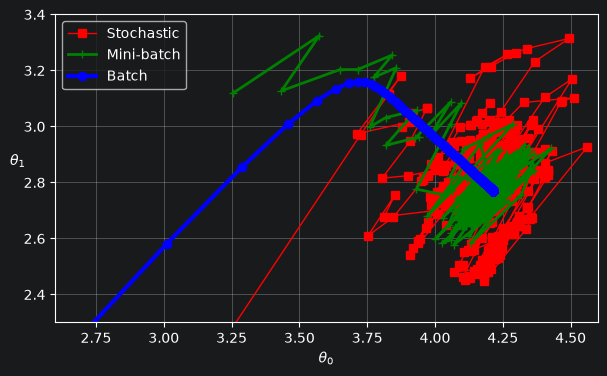

In [7]:
theta_path_bgd = np.array(theta_path_bgd)
theta_path_sgd = np.array(theta_path_sgd)
theta_path_mgd = np.array(theta_path_mgd)

plt.figure(figsize=(7, 4))
plt.plot(theta_path_sgd[:, 0], theta_path_sgd[:, 1], "r-s", linewidth=1, label="Stochastic")
plt.plot(theta_path_mgd[:, 0], theta_path_mgd[:, 1], "g-+", linewidth=2, label="Mini-batch")
plt.plot(theta_path_bgd[:, 0], theta_path_bgd[:, 1], "b-o", linewidth=3, label="Batch")
plt.legend(loc="upper left")
plt.xlabel(r"$\theta_0$")
plt.ylabel(r"$\theta_1$", rotation=0)
plt.axis([2.6, 4.6, 2.3, 3.4])
plt.grid()
plt.show()


Batch's path (blue) is smooth and direct — it always has the true, full gradient available.
Stochastic's path (red) is jagged, and keeps bouncing around near the optimum instead of
settling exactly on it. Mini-batch's path (green) sits in between: noisier than Batch, much
smoother than Stochastic. This one picture is really the whole batch-vs-stochastic-vs-mini-batch
trade-off, visually.


### 2.9 — Summary

| | Batch GD | Stochastic GD | Mini-batch GD |
|---|---|---|---|
| Instances used per step | all $m$ | 1 (random) | small batch (e.g. 20-few hundred) |
| Cost per step | expensive | very cheap | cheap |
| Path to the minimum | smooth, direct | noisy, jumps around | in between |
| Works when data doesn't fit in memory? | No | Yes | Yes |
| Needs a learning schedule to converge tightly? | No — a small fixed $\eta$ works | Yes | Yes |
| Best suited for | small/medium datasets | huge datasets, online learning | the default in practice (esp. deep learning, thanks to GPU parallelism) |


## ✏️ Check your understanding

1. Why does SGD *not* divide its gradient by $m$, while Batch GD does?
2. If you used a **constant** learning rate with SGD instead of a learning schedule, what would
   you expect to happen as training goes on?
3. For a dataset with 5 features and 10,000 instances, which would you reach for — the Normal
   Equation or Gradient Descent? What about 100,000 features?


**Answers**

1. Batch GD's gradient is literally the *average* over all $m$ instances — the true gradient of
   the full MSE — so dividing by $m$ gives the correct average. SGD's gradient uses a single
   instance as a stand-in *estimate* for that average; there's nothing to average over, so no
   division by $m$ — it's just that one instance's contribution, used directly.
2. It would keep bouncing around near the minimum indefinitely, at roughly the same "noise
   level", rather than settling down and converging more precisely — because the step size never
   shrinks, later steps stay just as large (and just as prone to overshoot) as the very first
   ones.
3. With 5 features, $(\mathbf X^\top \mathbf X)^{-1}$ is just a $5\times 5$ matrix inverse —
   essentially free — so the Normal Equation is the easy choice. With 100,000 features, that
   becomes a $100{,}000 \times 100{,}000$ inverse, which is computationally infeasible; Gradient
   Descent (mini-batch or SGD, in practice) is the only realistic option.


---
### Up next

Part 3 will cover **Polynomial Regression** — fitting curves, not just lines, using ordinary
linear regression — and **learning curves**, the standard tool for diagnosing whether a model is
underfitting or overfitting.
